In [156]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plot
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
import sklearn.metrics
from sklearn.metrics import explained_variance_score, mean_squared_error, r2_score # https://scikit-learn.org/stable/auto_examples/linear_model/plot_ols.html
import statsmodels.api as sm
import pandas
import matplotlib.pyplot as plt
import scipy as sp
from scipy.odr import *
import random
import operator

# For 3d plots. This import is necessary to have 3D plotting below
from mpl_toolkits.mplot3d import Axes3D

# For statistics. Requires statsmodels 5.0 or more
from statsmodels.formula.api import ols
from statsmodels.formula.api import wls
# Analysis of Variance (ANOVA) on linear models
from statsmodels.stats.anova import anova_lm

# Adapted from:
# https://www.datasciencecentral.com/profiles/blogs/linear-regression-in-python-use-of-numpy-scipy-and-statsmodels,
# https://realpython.com/linear-regression-in-python/#multiple-linear-regression

In [157]:
M0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundMStarData.csv',delimiter=',',skip_header=0)))
M1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneMStarData.csv',delimiter=',',skip_header=0)))
C0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundamentalCStarData.csv',delimiter=',',skip_header=0)))
C1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneCStarData.csv',delimiter=',',skip_header=0)))

In [158]:
MdotIndex=5 # Column of imported files that has Mdot data
MdotErrorIndex=6 # Absolute error in Mdot
#MdotIndex=2 # Column of imported files that has Mdot_dust Data
LIndex=8 # Column of imported files that has LBol data
LErrorIndex=9 # Absolute error in L
PIndex=13 # Column of imported files that has Period data
MIndex=22 # Column of imported files that has Mass data
RIndex=23 # Column of imported files that has Radius data
TeffObsvIndex=12 # Column of imported files that has Observed Teff Data
TeffCalcIndex=24 # Column of imported files that has Calculated Teff Data

In [159]:
logMdotData = np.log10(M0StarData[MdotIndex])

In [160]:
Reimers_eta = 1
Reimers_Mdot = Reimers_eta*(4*10**(-13))*(M0StarData[LIndex]*M0StarData[RIndex]/M0StarData[MIndex])
log10_Reimers_Mdot = np.log10(Reimers_Mdot)

In [161]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMdotData
y = log10_Reimers_Mdot

data = pandas.DataFrame({'logMdotData': x0, 'logMdot_PdivLM': y})

# Fit the model
model = ols("logMdot_PdivLM ~ logMdotData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
ReimersFitLineCoeff = model._results.params # Defines the quality-of-fit line with array (intercept, slope)

In [162]:
M0StarData[MdotIndex] 

array([2.82321670e-07, 1.17163493e-07, 3.24669921e-07, ...,
       2.82321670e-07, 2.54089503e-07, 5.92875508e-08])

In [163]:
def Vassiliadis_Wood_M_dot (P_array,M_array):
    i = 0
    Mdot_array = []
    M_dot = 0
    for i in range (0, len(P_array)):
        P = P_array[i]
        M = M_array[i]
        if M_array[i] >= 2.5:
            M_dot = 4*10**(-12)*10**(0.0123*P)
        else:
            M_dot = 4*10**(-12)*10**(0.0124*(P-100*(M-2.5)))
        Mdot_array.append(M_dot)
    return np.asarray(Mdot_array)

Vassiliadis_Wood_Mdot = Vassiliadis_Wood_M_dot (M0StarData[PIndex],M0StarData[MIndex])
log10_Vassiliadis_Wood_Mdot = np.log10(Vassiliadis_Wood_Mdot)

In [164]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMdotData
y = log10_Vassiliadis_Wood_Mdot

data = pandas.DataFrame({'logMdotData': x0, 'logMdot_PdivLM': y})

# Fit the model
model = ols("logMdot_PdivLM ~ logMdotData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
VWFitLineCoeff = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print(VWFitLineCoeff)

[-3.22733702  0.64327441]


In [165]:
Blocker_Mdot = 1.932*10**(-21)*M0StarData[MIndex]**(-3.1)*M0StarData[LIndex]**(3.7)*M0StarData[RIndex]
log10_Blocker_Mdot = np.log10(Blocker_Mdot)

In [166]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMdotData
y = log10_Blocker_Mdot

data = pandas.DataFrame({'logMdotData': x0, 'logMdot_PdivLM': y})

# Fit the model
model = ols("logMdot_PdivLM ~ logMdotData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
BlockerFitLineCoeff = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print(BlockerFitLineCoeff)

[-3.02478054  0.36715894]


In [167]:
log10_Q_Mdot = 8.935752177734368 + ( 8.406346957796341 )*np.log10(M0StarData[PIndex]) + ( -9.710197122513199 )*np.log10(M0StarData[LIndex]) +  7.489751883786768*np.log10(M0StarData[MIndex])

In [168]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMdotData
y = log10_Q_Mdot

data = pandas.DataFrame({'logMdotData': x0, 'logMdot_PdivLM': y})

# Fit the model
model = ols("logMdot_PdivLM ~ logMdotData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
QFitLineCoeff = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print(QFitLineCoeff)

[-5.10167483  0.24707475]


In [169]:
log10_Qx_Mdot = 10.759585256755166 + ( 9.087206275719318 )*np.log10(M0StarData[PIndex]) + ( -10.653781572896197 )*np.log10(M0StarData[LIndex]) +  8.33690166903896*np.log10(M0StarData[MIndex])

In [170]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMdotData
y = log10_Qx_Mdot

data = pandas.DataFrame({'logMdotData': x0, 'logMdot_PdivLM': y})

# Fit the model
model = ols("logMdot_PdivLM ~ logMdotData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
QxFitLineCoeff = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print(QxFitLineCoeff)

[-5.09002064  0.24879472]


In [171]:
log10_Qz_Mdot = 1.5116904513774951 + ( 5.424393750697673 )*np.log10(M0StarData[PIndex]) + ( -5.739427581756874 )*np.log10(M0StarData[LIndex]) +  4.3629145303546135*np.log10(M0StarData[MIndex])

In [172]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMdotData
y = log10_Qz_Mdot

data = pandas.DataFrame({'logMdotData': x0, 'logMdot_PdivLM': y})

# Fit the model
model = ols("logMdot_PdivLM ~ logMdotData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
QzFitLineCoeff = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print(QzFitLineCoeff)

[-5.37751311  0.20636545]


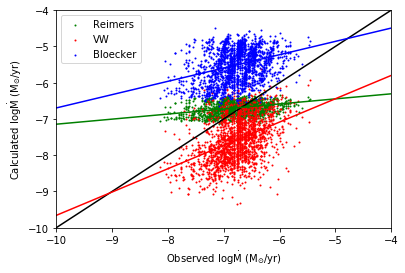

In [189]:

plt.plot((-10,-4),(-10,-4),marker='',color='k')

plt.scatter(np.log10(M0StarData[MdotIndex]),log10_Reimers_Mdot,marker='.', s=4, label = 'Reimers',color ='green')
ReimersLine=ReimersFitLineCoeff[0] +ReimersFitLineCoeff[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),ReimersLine, color='green')

plt.scatter(np.log10(M0StarData[MdotIndex]),log10_Vassiliadis_Wood_Mdot,marker='.', s=4, label = 'VW', color = 'red')
VWLine=VWFitLineCoeff[0] + VWFitLineCoeff[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),VWLine, color='red')

plt.scatter(np.log10(M0StarData[MdotIndex]),log10_Blocker_Mdot,marker='.', s=4,label='Bloecker', color = 'blue')
BlockerLine=BlockerFitLineCoeff[0] + BlockerFitLineCoeff[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),BlockerLine, color='blue')

#plt.scatter(np.log10(M0StarData[MdotIndex]),log10_Q_Mdot,marker='>', s=10, color='orange', label='Q')
#QLine=QFitLineCoeff[0] + QFitLineCoeff[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
#plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),QLine, color='orange')

#plt.scatter(np.log10(M0StarData[MdotIndex]),log10_Qx_Mdot,marker='<', s=10, color='m', label='Qx')
#QxLine=QxFitLineCoeff[0] + QxFitLineCoeff[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
#plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),QxLine, color='m')

#plt.scatter(np.log10(M0StarData[MdotIndex]),log10_Qz_Mdot,marker='^', s=10, color='c', label='Qz')
#QzLine=QzFitLineCoeff[0] + QzFitLineCoeff[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
#plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),QzLine, color='c')


plot.xlabel(r'$ \mathrm{Observed\ \log \dot{M}\ (M_{\odot}/yr)}$')
plot.ylabel(r'$ \mathrm{Calculated\ \log \dot{M}\ (M_{\odot}/yr)}$')
plot.xlim(-10,-4)
plot.ylim(-10,-4)
plot.legend()

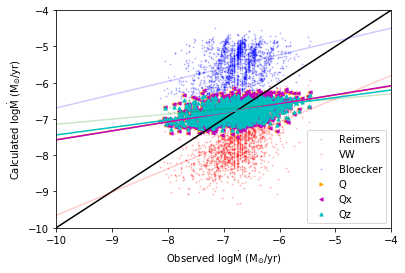

In [188]:

plt.plot((-10,-4),(-10,-4),marker='',color='k')

plt.scatter(np.log10(M0StarData[MdotIndex]),log10_Reimers_Mdot,marker='.', s=4, label = 'Reimers',color ='green', alpha=0.2)
ReimersLine=ReimersFitLineCoeff[0] +ReimersFitLineCoeff[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),ReimersLine, color='green', alpha=0.2)

plt.scatter(np.log10(M0StarData[MdotIndex]),log10_Vassiliadis_Wood_Mdot,marker='.', s=4, label = 'VW', color = 'red', alpha=0.2)
VWLine=VWFitLineCoeff[0] + VWFitLineCoeff[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),VWLine, color='red', alpha=0.2)

plt.scatter(np.log10(M0StarData[MdotIndex]),log10_Blocker_Mdot,marker='.', s=4,label='Bloecker', color = 'blue', alpha=0.2)
BlockerLine=BlockerFitLineCoeff[0] + BlockerFitLineCoeff[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),BlockerLine, color='blue', alpha=0.2)

plt.scatter(np.log10(M0StarData[MdotIndex]),log10_Q_Mdot,marker='>', s=10, color='orange', label='Q')
QLine=QFitLineCoeff[0] + QFitLineCoeff[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),QLine, color='orange')

plt.scatter(np.log10(M0StarData[MdotIndex]),log10_Qx_Mdot,marker='<', s=10, color='m', label='Qx')
QxLine=QxFitLineCoeff[0] + QxFitLineCoeff[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),QxLine, color='m')

plt.scatter(np.log10(M0StarData[MdotIndex]),log10_Qz_Mdot,marker='^', s=10, color='c', label='Qz')
QzLine=QzFitLineCoeff[0] + QzFitLineCoeff[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),QzLine, color='c')


plot.xlabel(r'$ \mathrm{Observed\ \log \dot{M}\ (M_{\odot}/yr)}$')
plot.ylabel(r'$ \mathrm{Calculated\ \log \dot{M}\ (M_{\odot}/yr)}$')
plot.xlim(-10,-4)
plot.ylim(-10,-4)
plot.legend()